In [1]:
!pip install -U tensorflow opencv-python lxml matplotlib scikit-learn


In [2]:
import os
import numpy as np
import tensorflow as tf
import xml.etree.ElementTree as ET
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.preprocessing import LabelEncoder
import matplotlib.pyplot as plt
import seaborn as sns
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras import layers, models


In [3]:
from roboflow import Roboflow
rf = Roboflow(api_key="YKjKJq9jwCbXAUxun5s3")
project = rf.workspace("work-4u6cx").project("yolv5-detection")
version = project.version(5)
dataset = version.download("voc")

# Define base and train/val directories (flat structure)
base_path = dataset.location
train_dir = os.path.join(base_path, "train")
val_dir = os.path.join(base_path, "valid")


loading Roboflow workspace...
loading Roboflow project...


In [4]:
# After downloading
dataset = version.download("voc")
print("Dataset location:", dataset.location)

# Update paths
base_path = dataset.location
train_img_dir = os.path.join(base_path, "train", "images")
train_ann_dir = os.path.join(base_path, "train", "annotations")
val_img_dir = os.path.join(base_path, "valid", "images")
val_ann_dir = os.path.join(base_path, "valid", "annotations")


Dataset location: /content/YOLV5-Detection-5


In [5]:
# Parse first object name from Pascal VOC XML
def parse_voc(xml_path):
    tree = ET.parse(xml_path)
    root = tree.getroot()
    for obj in root.findall("object"):
        return obj.find("name").text  # First object label

# Load images and labels from a flat directory
def load_dataset(flat_dir, target_size=(224, 224)):
    X, y = [], []
    for fname in os.listdir(flat_dir):
        if fname.endswith(".jpg") or fname.endswith(".png"):
            image_path = os.path.join(flat_dir, fname)
            xml_path = os.path.splitext(image_path)[0] + ".xml"
            if os.path.exists(xml_path):
                img = tf.keras.preprocessing.image.load_img(image_path, target_size=target_size)
                img = tf.keras.preprocessing.image.img_to_array(img) / 255.0
                label = parse_voc(xml_path)
                X.append(img)
                y.append(label)
    return np.array(X), np.array(y)


In [6]:
X_train, y_train = load_dataset(train_dir)
X_val, y_val = load_dataset(val_dir)

le = LabelEncoder()
y_train_enc = le.fit_transform(y_train)
y_val_enc = le.transform(y_val)
num_classes = len(le.classes_)


In [7]:
base_model = MobileNetV2(input_shape=(224, 224, 3), include_top=False, weights='imagenet')
base_model.trainable = False  # Freeze base layers

model = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation='relu'),
    layers.Dense(num_classes, activation='softmax')
])

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])


In [8]:
history = model.fit(
    X_train, y_train_enc,
    validation_data=(X_val, y_val_enc),
    epochs=300,
    batch_size=32,
    verbose=2
)


Epoch 1/300
94/94 - 43s - 461ms/step - accuracy: 0.7117 - loss: 0.9241 - val_accuracy: 0.7289 - val_loss: 0.7494
Epoch 2/300
94/94 - 1s - 13ms/step - accuracy: 0.8330 - loss: 0.4873 - val_accuracy: 0.7887 - val_loss: 0.5527
Epoch 3/300
94/94 - 1s - 13ms/step - accuracy: 0.8940 - loss: 0.3132 - val_accuracy: 0.8239 - val_loss: 0.5137
Epoch 4/300
94/94 - 1s - 13ms/step - accuracy: 0.9400 - loss: 0.2006 - val_accuracy: 0.8310 - val_loss: 0.4801
Epoch 5/300
94/94 - 1s - 13ms/step - accuracy: 0.9643 - loss: 0.1381 - val_accuracy: 0.8627 - val_loss: 0.4527
Epoch 6/300
94/94 - 1s - 13ms/step - accuracy: 0.9757 - loss: 0.1003 - val_accuracy: 0.8592 - val_loss: 0.4556
Epoch 7/300
94/94 - 1s - 14ms/step - accuracy: 0.9830 - loss: 0.0787 - val_accuracy: 0.8592 - val_loss: 0.4446
Epoch 8/300
94/94 - 1s - 13ms/step - accuracy: 0.9877 - loss: 0.0607 - val_accuracy: 0.8732 - val_loss: 0.4373
Epoch 9/300
94/94 - 1s - 13ms/step - accuracy: 0.9920 - loss: 0.0473 - val_accuracy: 0.8768 - val_loss: 0.4495

9/9 ━━━━━━━━━━━━━━━━━━━━ 7s 426ms/step
Classification Report:

                 precision    recall  f1-score   support

        Adaptor       1.00      1.00      1.00         1
    Bit Sockets       0.83      0.62      0.71        16
           Bits       1.00      1.00      1.00         2
    Deep Socket       0.90      0.81      0.85        69
  Extension Bar       0.78      0.64      0.70        11
    Flex Handle       0.50      0.75      0.60         4
 Rachet-Handels       0.50      0.50      0.50        10
        Sockets       0.90      0.96      0.93       156
long bit socket       0.92      1.00      0.96        12
universal joint       0.67      0.67      0.67         3

       accuracy                           0.87       284
      macro avg       0.80      0.80      0.79       284
   weighted avg       0.87      0.87      0.87       284



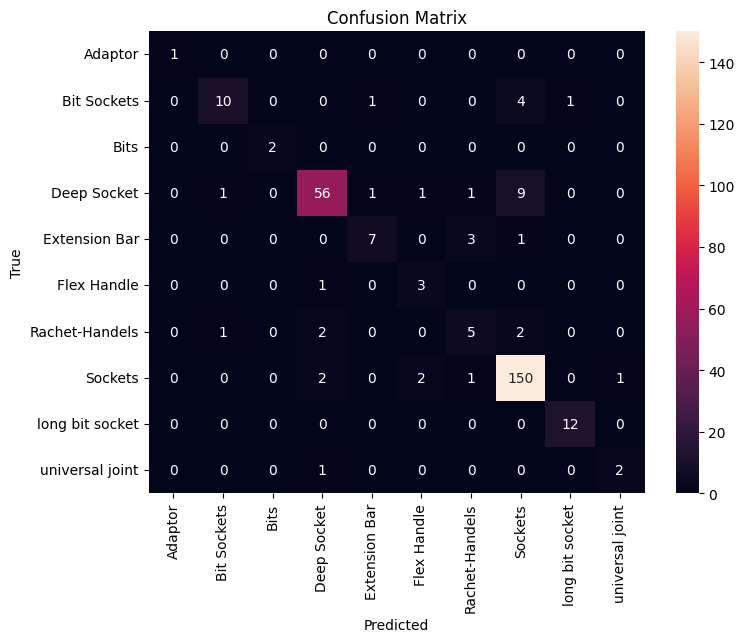

In [9]:
# Predict
y_pred = model.predict(X_val)
y_pred_classes = np.argmax(y_pred, axis=1)

# Print classification report
print("Classification Report:\n")
print(classification_report(y_val_enc, y_pred_classes, target_names=le.classes_))

# Plot confusion matrix
cm = confusion_matrix(y_val_enc, y_pred_classes)
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=le.classes_, yticklabels=le.classes_)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()


In [11]:
from tensorflow.keras.callbacks import ModelCheckpoint

# Correct file name extension for saving only weights
checkpoint_path = "mobilenet_best.weights.h5"

checkpoint = ModelCheckpoint(
    filepath=checkpoint_path,
    monitor='val_accuracy',
    save_best_only=True,
    save_weights_only=True,  # <-- only weights, not the full model
    verbose=1
)

# Training with callback
history = model.fit(
    X_train, y_train_enc,
    validation_data=(X_val, y_val_enc),
    epochs=300,
    batch_size=32,
    callbacks=[checkpoint],
    verbose=2
)


Epoch 1/300

Epoch 1: val_accuracy improved from -inf to 0.87324, saving model to mobilenet_best.weights.h5
94/94 - 2s - 18ms/step - accuracy: 1.0000 - loss: 2.7554e-05 - val_accuracy: 0.8732 - val_loss: 1.2965
Epoch 2/300

Epoch 2: val_accuracy improved from 0.87324 to 0.87676, saving model to mobilenet_best.weights.h5
94/94 - 2s - 16ms/step - accuracy: 1.0000 - loss: 2.5640e-05 - val_accuracy: 0.8768 - val_loss: 1.2974
Epoch 3/300

Epoch 3: val_accuracy did not improve from 0.87676
94/94 - 1s - 13ms/step - accuracy: 1.0000 - loss: 2.3357e-05 - val_accuracy: 0.8768 - val_loss: 1.3014
Epoch 4/300

Epoch 4: val_accuracy did not improve from 0.87676
94/94 - 1s - 13ms/step - accuracy: 1.0000 - loss: 2.2645e-05 - val_accuracy: 0.8768 - val_loss: 1.3022
Epoch 5/300

Epoch 5: val_accuracy did not improve from 0.87676
94/94 - 1s - 12ms/step - accuracy: 1.0000 - loss: 2.1749e-05 - val_accuracy: 0.8768 - val_loss: 1.3032
Epoch 6/300

Epoch 6: val_accuracy did not improve from 0.87676
94/94 - 1s